In [2]:
# How are in demand skills trending for Data Analysts jobs in the UK?

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns   
import numpy as np
import ast


from datasets import load_dataset

loaded_dataset = load_dataset("lukebarousse/data_jobs")

df = loaded_dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notnull(x) else x)

In [ ]:
df_DA_UK = df[(df['job_title'] == 'Data Analyst') & (df['job_country'] == 'United Kingdom')].copy()

df_DA_UK

In [5]:
df_DA_UK['job_posted_month_no'] = df_DA_UK['job_posted_date'].dt.month

In [6]:
df_DE_UK_explode = df_DA_UK.explode('job_skills')


In [ ]:
df_DA_UK_pivot = df_DE_UK_explode.pivot_table(index='job_posted_month_no', columns='job_skills',aggfunc='size', fill_value=0)

df_DA_UK_pivot.loc['Total'] = df_DA_UK_pivot.sum()

df_DA_UK_pivot =df_DA_UK_pivot[df_DA_UK_pivot.loc['Total'].sort_values(ascending=False).index]

df_DA_UK_pivot = df_DA_UK_pivot.drop('Total')

df_DA_UK_pivot

In [8]:
DA_Total = df_DA_UK.groupby('job_posted_month_no').size()

In [ ]:
# use .div

df_DA_UK_Percent = df_DA_UK_pivot.div(DA_Total, axis=0) * 100

df_DA_UK_Percent

In [ ]:
# Changes month numbers to month name using lambda function and map
df_DA_UK_Percent = df_DA_UK_Percent.reset_index()

df_DA_UK_Percent['job_posted_month'] = df_DA_UK_Percent['job_posted_month_no'].apply(lambda x: pd.to_datetime(x, format='%m').strftime('%b'))

df_DA_UK_Percent = df_DA_UK_Percent.set_index('job_posted_month')

df_DA_UK_Percent = df_DA_UK_Percent.drop('job_posted_month_no', axis=1)

df_DA_UK_Percent

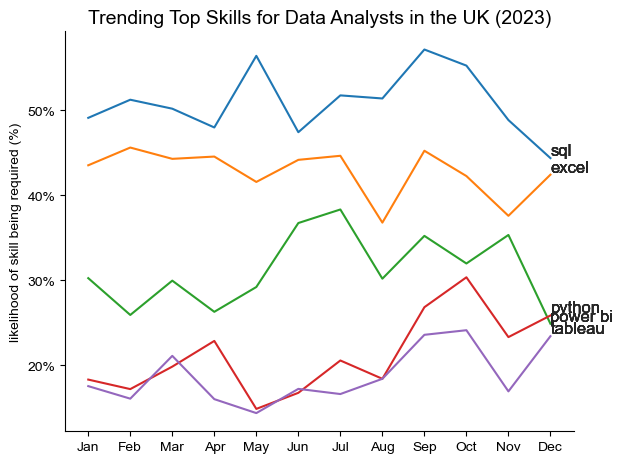

In [11]:
# plot the line chart for the top 5 skills
df_plot = df_DA_UK_Percent.iloc[:, :5]

sns.lineplot(data=df_plot, dashes = False, palette='tab10')
sns.set_theme(style="ticks")
sns.despine()

plt.title('Trending Top Skills for Data Analysts in the UK (2023)', fontsize=14)
plt.xlabel('')
plt.ylabel('likelihood of skill being required (%)')
plt.legend().remove()
#plt.ylim(0, 60)


#format y-axis to show percentage

from matplotlib.ticker import PercentFormatter
ax = plt.gca()
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))


for i in range(len(df_plot.columns)):
    for i in range(len(df_plot.columns)):
        plt.text(
            x=df_plot.index[-1],
            y=df_plot.iloc[-1, i],
            s=df_plot.columns[i],
            va='bottom',
            ha='left',
        )

plt.tight_layout()               # Adjust spacing around the chart



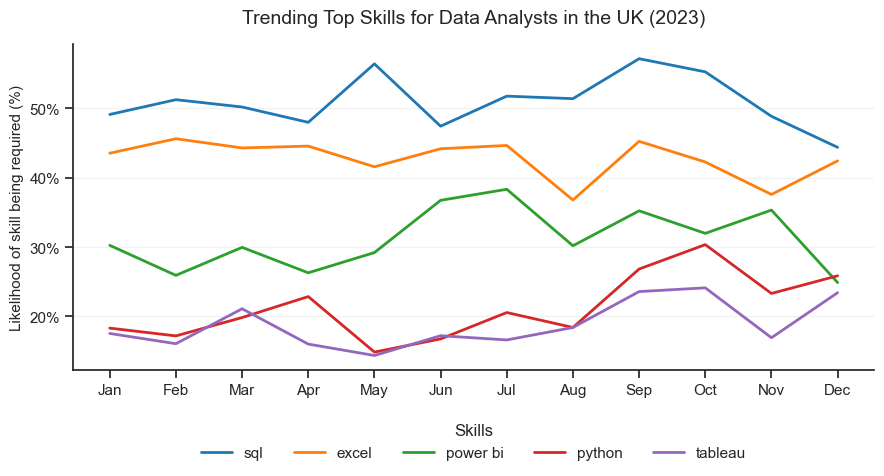

In [13]:
# Set chart theme
sns.set_theme(style='ticks')

# Plot the line chart for the top 5 skills
df_plot = df_DA_UK_Percent.iloc[:, :5]

plt.figure(figsize=(9, 5))

ax = sns.lineplot(
    data=df_plot,
    dashes=False,
    palette='tab10',
    linewidth=2
)

sns.despine()

# Chart title and labels
plt.title('Trending Top Skills for Data Analysts in the UK (2023)',
          fontsize=14, pad=15)

plt.xlabel('')
plt.ylabel('Likelihood of skill being required (%)', fontsize=11)

# Format y-axis to show percentages
from matplotlib.ticker import PercentFormatter

ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))

# Subtle horizontal gridlines
ax.grid(axis='y', alpha=0.25)
ax.grid(axis='x', visible=False)

# Position legend below the chart
plt.legend(
    title='Skills',
    loc='upper center',
    bbox_to_anchor=(0.5, -0.12),
    ncol=5,
    frameon=False
)

plt.tight_layout()